# Museum Night Shift — MDPs & Dynamic Programming

**Goal:** Model a real-world navigation problem as an MDP and solve it using **Value Iteration** and **Policy Iteration**, then visualize the resulting policy and value function.


## 1. Problem Setup

A security robot patrols a museum at night.

- Start: **S**
- Goal: **G** (terminal, reward +1)
- Trap: **T** (terminal, reward −1)
- Walls: **#**
- Empty cells: **.**
- Each step costs: reward **−0.04**
- Actions are **stochastic**: intended action succeeds with probability **1−ε**, otherwise slips left/right.

### Grid (6×6)
```
S . . # . .
. # . # . .
. # . . . .
. . # # . T
# . . . # .
. . # . . G
```


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import random

np.set_printoptions(precision=3, suppress=True)

GRID = [
    "S..#..",
    ".#.#..",
    ".#....",
    "..##.T",
    "#...#.",
    "..#..G"
]

N_ROWS = len(GRID)
N_COLS = len(GRID[0])

ACTIONS = ["UP", "RIGHT", "DOWN", "LEFT"]
ACTION_TO_DELTA = {
    "UP":    (-1, 0),
    "RIGHT": (0, 1),
    "DOWN":  (1, 0),
    "LEFT":  (0, -1),
}
LEFT_OF = {"UP":"LEFT","LEFT":"DOWN","DOWN":"RIGHT","RIGHT":"UP"}
RIGHT_OF = {"UP":"RIGHT","RIGHT":"DOWN","DOWN":"LEFT","LEFT":"UP"}

STEP_COST = -0.04
GAMMA = 0.99
EPSILON = 0.2

def is_terminal(r, c):
    return GRID[r][c] in ("G", "T")

def terminal_reward(r, c):
    if GRID[r][c] == "G":
        return 1.0
    if GRID[r][c] == "T":
        return -1.0
    return 0.0

## 2. State Enumeration

Map each non-wall cell to an integer index for use in the DP algorithms.

In [2]:
def enumerate_states(grid):
    state_to_idx = {}
    idx_to_state = []
    for r in range(N_ROWS):
        for c in range(N_COLS):
            if grid[r][c] != "#":
                idx = len(idx_to_state)
                state_to_idx[(r,c)] = idx
                idx_to_state.append((r,c))
    return state_to_idx, idx_to_state

state_to_idx, idx_to_state = enumerate_states(GRID)
N_STATES = len(idx_to_state)
N_ACTIONS = len(ACTIONS)
print("Number of states:", N_STATES)

Number of states: 27


## 3. Transition and Reward Model

Implement the stochastic transition function and the reward function.

In [3]:
def deterministic_step(state, action):
    r, c = state
    dr, dc = ACTION_TO_DELTA[action]
    nr, nc = r + dr, c + dc
    if nr < 0 or nr >= N_ROWS or nc < 0 or nc >= N_COLS:
        return (r,c)
    if GRID[nr][nc] == "#":
        return (r,c)
    return (nr,nc)

In [4]:
def transition_probs(state, action, eps=EPSILON):
    if is_terminal(*state):
        return [(1.0, state)]
    outcomes = []
    for prob, act in [
        (1-eps, action),
        (eps/2, LEFT_OF[action]),
        (eps/2, RIGHT_OF[action]),
    ]:
        outcomes.append((prob, deterministic_step(state, act)))
    return outcomes

In [5]:
def reward(state, action, next_state):
    r, c = next_state
    if is_terminal(r,c):
        return terminal_reward(r,c)
    return STEP_COST

## 4. Build the Full MDP Transition Table

Precompute `P[s][a] = list of (probability, next_state, reward)` for all state-action pairs.

In [6]:
P = defaultdict(lambda: defaultdict(list))

for s_idx, s in enumerate(idx_to_state):
    for a_idx, a in enumerate(ACTIONS):
        for p, s_next in transition_probs(s, a):
            r = reward(s, a, s_next)
            s_next_idx = state_to_idx[s_next]
            P[s_idx][a_idx].append((p, s_next_idx, r))

print("Built transitions for", N_STATES, "states.")

Built transitions for 27 states.


## 5. Value Iteration

Iteratively apply the Bellman optimality update until convergence (max change < θ).

In [7]:
def value_iteration(P, gamma=GAMMA, theta=1e-6, max_iters=100000):
    V = np.zeros(N_STATES)
    it = 0
    while True:
        it += 1
        delta = 0.0
        for s in range(N_STATES):
            v_old = V[s]
            q_vals = []
            for a in range(N_ACTIONS):
                q = 0.0
                for p, s_next, r in P[s][a]:
                    q += p * (r + gamma * V[s_next])
                q_vals.append(q)
            V[s] = max(q_vals)
            delta = max(delta, abs(v_old - V[s]))
        if delta < theta or it >= max_iters:
            break
    return V, it

In [8]:
def extract_greedy_policy(V, gamma=GAMMA):
    pi = np.zeros(N_STATES, dtype=int)
    for s in range(N_STATES):
        q_vals = []
        for a in range(N_ACTIONS):
            q = 0.0
            for p, s_next, r in P[s][a]:
                q += p * (r + gamma * V[s_next])
            q_vals.append(q)
        pi[s] = int(np.argmax(q_vals))
    return pi

In [9]:
V_star, vi_iters = value_iteration(P)
pi_star = extract_greedy_policy(V_star)
print("VI iters:", vi_iters)

VI iters: 1376


## 6. Policy Iteration

Alternate between full policy evaluation and greedy policy improvement until the policy stabilizes.

In [10]:
def policy_evaluation(pi, P, gamma=GAMMA, theta=1e-6, max_sweeps=100000):
    V = np.zeros(N_STATES)
    sweeps = 0
    while True:
        sweeps += 1
        delta = 0.0
        for s in range(N_STATES):
            v_old = V[s]
            a = int(pi[s])
            v_new = 0.0
            for p, s_next, r in P[s][a]:
                v_new += p * (r + gamma * V[s_next])
            V[s] = v_new
            delta = max(delta, abs(v_old - V[s]))
        if delta < theta or sweeps >= max_sweeps:
            break
    return V, sweeps

In [11]:
def policy_iteration(P, gamma=GAMMA, theta_eval=1e-6):
    pi = np.random.randint(N_ACTIONS, size=N_STATES)
    outer = 0
    total_sweeps = 0
    while True:
        outer += 1
        V, sweeps = policy_evaluation(pi, P, gamma=gamma, theta=theta_eval)
        total_sweeps += sweeps

        stable = True
        for s in range(N_STATES):
            old = int(pi[s])
            q_vals = []
            for a in range(N_ACTIONS):
                q = 0.0
                for p, s_next, r in P[s][a]:
                    q += p * (r + gamma * V[s_next])
                q_vals.append(q)
            pi[s] = int(np.argmax(q_vals))
            if int(pi[s]) != old:
                stable = False

        if stable:
            break
    return pi, V, outer, total_sweeps

In [12]:
pi_pi, V_pi, pi_outer, pi_sweeps = policy_iteration(P)
print("PI outer iters:", pi_outer, "policy-eval sweeps:", pi_sweeps)

PI outer iters: 5 policy-eval sweeps: 6880


## 7. Visualization

Plot the value function as a heatmap and overlay the greedy policy arrows.

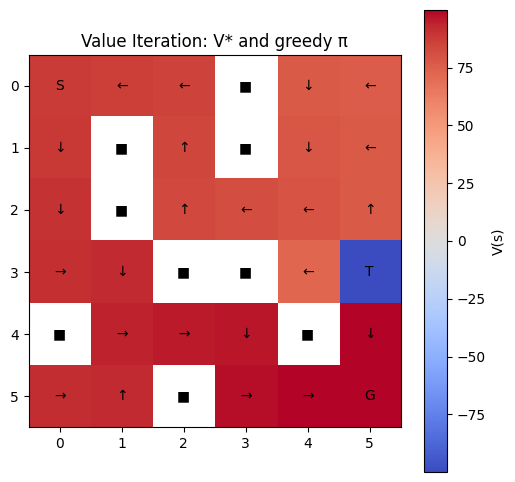

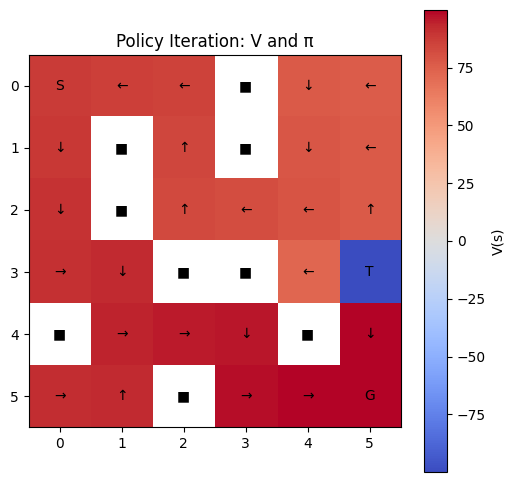

In [13]:
ARROWS = ["↑","→","↓","←"]

def plot_policy_and_values(V, pi, title="Policy and Value"):
    grid_V = np.full((N_ROWS, N_COLS), np.nan)
    grid_pi = np.full((N_ROWS, N_COLS), "", dtype=object)
    for idx, (r,c) in enumerate(idx_to_state):
        grid_V[r,c] = V[idx]
        grid_pi[r,c] = ARROWS[pi[idx]]

    plt.figure(figsize=(6,6))
    plt.imshow(grid_V, cmap="coolwarm")
    plt.colorbar(label="V(s)")
    for r in range(N_ROWS):
        for c in range(N_COLS):
            if GRID[r][c] == "#":
                plt.text(c, r, "■", ha="center", va="center", color="black")
            elif GRID[r][c] in ("G","T","S"):
                plt.text(c, r, GRID[r][c], ha="center", va="center", color="black")
            else:
                plt.text(c, r, grid_pi[r,c], ha="center", va="center", color="black")
    plt.title(title)
    plt.show()

plot_policy_and_values(V_star, pi_star, title="Value Iteration: V* and greedy π")
plot_policy_and_values(V_pi, pi_pi, title="Policy Iteration: V and π")

## 8. Policy Evaluation via Simulation

Roll out the learned policy and measure empirical success rate and average return.

In [14]:
def simulate(start_state, pi, max_steps=200, eps=EPSILON):
    s = start_state
    total = 0.0
    steps = 0
    for _ in range(max_steps):
        steps += 1
        if is_terminal(*s):
            break
        s_idx = state_to_idx[s]
        a = ACTIONS[pi[s_idx]]
        transitions = transition_probs(s, a, eps=eps)
        probs, next_states = zip(*transitions)
        s_next = random.choices(next_states, probs)[0]
        total += reward(s, a, s_next)
        s = s_next
    return total, s, steps

def find_start():
    for r in range(N_ROWS):
        for c in range(N_COLS):
            if GRID[r][c] == "S":
                return (r,c)
    raise RuntimeError("No start state S found")

start = find_start()

R = []
ends = {"G":0, "T":0, "other":0}
for _ in range(50):
    ret, end_state, steps = simulate(start, pi_star)
    R.append(ret)
    ch = GRID[end_state[0]][end_state[1]]
    if ch == "G": ends["G"] += 1
    elif ch == "T": ends["T"] += 1
    else: ends["other"] += 1

print("Rollouts (50) under VI greedy policy:")
print("  reach G:", ends["G"], "reach T:", ends["T"], "other:", ends["other"])
print("  avg return:", float(np.mean(R)))

Rollouts (50) under VI greedy policy:
  reach G: 50 reach T: 0 other: 0
  avg return: 0.4872000000000001


## 9. Theory: Bellman Operator is a Contraction

The Bellman expectation operator $T^\pi$ is a contraction under the $\ell_\infty$ norm:

$$
\|T^\pi V - T^\pi W\|_\infty
= \max_s \left| \sum_{s'} P(s' \mid s, \pi(s)) \, \gamma \big( V(s') - W(s') \big) \right|
\le \gamma \cdot \|V - W\|_\infty
$$

Since $\gamma < 1$, repeated application converges to a unique fixed point $V^\pi$.


## 10. Discussion

**Value Iteration vs Policy Iteration**  
Value Iteration requires many iterations (values propagate slowly); Policy Iteration converges in fewer outer iterations but each is more expensive due to full policy evaluation.

**Effect of discount factor γ**  
Higher γ → more far-sighted, more cautious near the trap. Lower γ → myopic, may take riskier shorter paths.

**Effect of stochasticity ε**  
Higher ε increases outcome uncertainty, raising the expected cost of risky actions and potentially restructuring the optimal policy.
